# PTM3D notebook 01: a global Moon over one lunar day

One lunar day (29.53 Earth days) of surface temperature over the whole Moon on a coarse global
mesh. This is the notebook version of [tutorial 1](../01_quickstart.md), with the same
configuration.

You will run the model, read its output, plot the maximum temperature and the diurnal cycle,
replace the smooth sphere with LOLA topography to see where slopes change the maximum temperature,
and change a thermophysical property and confirm that the change reached the thermal model.

**Cost:** a few minutes on four cores, under 1 GB of memory. The notebook makes seven runs. They
are the quickstart, four more 1,280-face runs for the thermal-inertia comparison in section 10, and two
20,480-face runs with and without topography. Radiation exchange is off in all of them, because
no face of a convex sphere sees another.

**Needs:** the `ptm` package (`pip install -e .` from the repository root), a built
`ptm_thermal_sim`, and the Moon SPICE kernels. The next cell checks all three and names the
command that supplies anything missing.

In [1]:
from ptm import paths, run as engine

CONFIG = "examples/quickstart_moon_diurnal.yaml"
pre = paths.preflight([CONFIG, "data/kernels/lsk/naif0012.tls"],
                      engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()

found    <repo>/build/bin/ptm_thermal_sim
found    examples/quickstart_moon_diurnal.yaml
found    data/kernels/lsk/naif0012.tls

Repo root: <repo>
Engine:    <repo>/build/bin/ptm_thermal_sim


<Report 3/3 found>

## 1. Run it

`run_engine` runs the model and waits for it to finish, and `.results()` opens the directory it
wrote. With `echo=True` the log is shown as the run proceeds, with one line for each quarter of
each progress bar.

The run takes about 10 seconds on four cores. The model uses every core it finds.

In [2]:
moon = engine.run_engine(pre.root / CONFIG, echo=True).results()

Running: <repo>/build/bin/ptm_thermal_sim --config <repo>/examples/quickstart_moon_diurnal.yaml
(cwd=<repo>)

╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: <repo>/examples/quickstart_moon_diurnal.yaml
✓ Configuration loaded from: <repo>/examples/quickstart_moon_diurnal.yaml
[gpu] Thermal dispatch target: 1.5 s (default)
Hapke albedo gate: body 

Loaded SPICE meta-kernel: <repo>/data/kernels/moon.tm
========== Thermal Equilibration Configuration ==========
Body: Moon
Synodic day (solar day): 29.5306 Earth days
Equilibration (configured): 80.00 day/night cycles  (thermal.equilibration_orbits)
Equilibration (integrated): 80.00 day/night cycles = 1 pass(es) x 80.00-cycle forcing block  [default]
Seed surface anchor: lumped  (cycle-mean lumped-substrate anchor; the run's per-face census and its QUADRATURE are printed by the solver)
Spin-up seed: physical  (shared per-face conductive steady profile, identical on every solver path)
Equilibration (analytic seed, CPU paths only): 0 day/night cycles  (OFF -- spin-up is the configured equilibration under the REAL forcing)
Total equilibration period: 2362.45 Earth days
Output window (for export): 29.53 Earth days
Requested integration (stats): 29.53 days with offset 0.00 days
Post-equilibration simulated span: 29.53 Earth days
Total simulation time: 2391.98 Earth days
Time step calculatio

Calculating illumination:  [============>                                     ] 25% | elapsed 1s, ETA 2s


Calculating illumination:  [=========================>                        ] 50% | elapsed 1s, ETA 1s


Calculating illumination:  [=====================================>            ] 75% | elapsed 2s, ETA 1s


Calculating illumination:  [==================================================] 100% | elapsed 2s
Illumination calculation completed in 2.540 seconds.
Results:
Average total flux: 452.245571185 W/m^2
- Direct solar: 452.213392842 W/m^2
- Primary reflected: 0.010269630 W/m^2
- Primary IR: 0.021908713 W/m^2
Maximum total flux: 1414.304396045 W/m^2
- Direct solar: 1414.304396045 W/m^2
- Primary reflected: 0.091775006 W/m^2
- Primary IR: 0.077236879 W/m^2
Minimum flux (non-zero): 0.000000000 W/m^2
Ray tracing computation completed in 2.542 seconds (2542 ms)
[cadence-advisor] not needed: no face on this mesh has an occluder between it and the Sun at the sampled sun positions, so there are no short sunlit flashes to miss.
[cadence-advisor]   Sun: angular rate omega = 0.508 deg/h (from the run's own sun directions), disk theta = 0.532 deg, theta/omega = 1.05 h.
[cadence-advisor]   Occluder probe: 0% of the area has an occluder between it and the Sun at some of the 64 sampled sun positions. Us

... (6 outputs left out)

Progress 61/240


Progress 133/240


Progress 193/240


Progress 240/240
Export complete: 240/240
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_moon_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 1280
Time steps: 240
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...
Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_moon_diurnal/statistics
[albedo] effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.154456 over 1280/1280 ever-lit faces; per-face -> output/quickstart_moon_diurnal/statistics/effective_albedo.bin (uint32 n + float32[1280], NaN where never lit).
Reduced over the INTEGRATION window, abs steps [3840,4080) -- the same window as 

## 2. The first look

Peak temperature at every face over the lunation, drawn as orthographic globes.

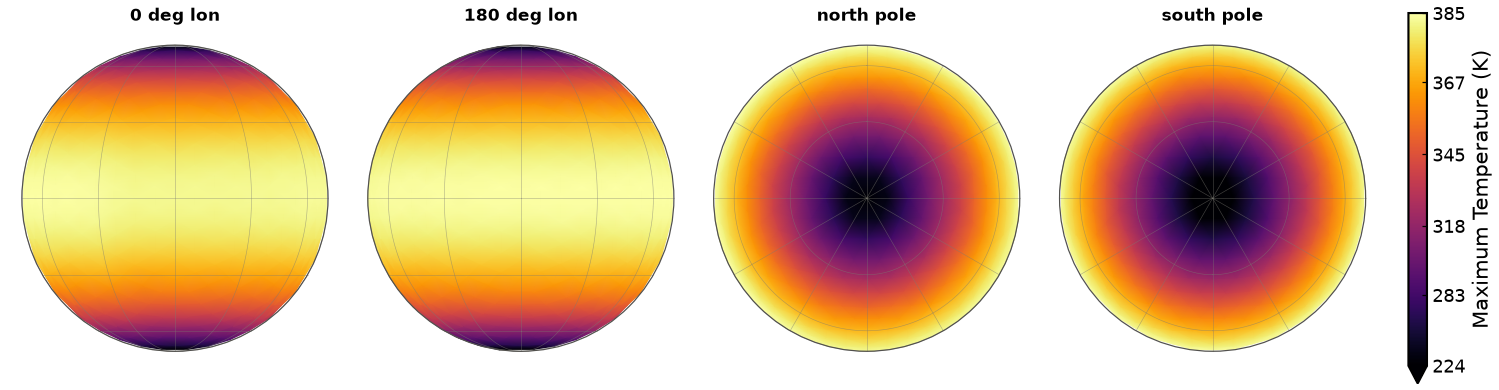

In [3]:
fig = moon.plot_globes("temperature", "max")

Three features of this map are important for what follows.

The field varies with latitude and not with longitude, as it must for a smooth sphere of uniform
material, because every meridian receives the same noon. Any variation with longitude in a later
run therefore comes from something added to the model.

The cold polar caps are small. A rectangular map stretches them across its whole width, but on
the globe each is a small patch.

The color scale is not linear in temperature. Section 5 explains why.

## 3. The configuration

[`examples/quickstart_moon_diurnal.yaml`](../../../examples/quickstart_moon_diurnal.yaml) is a small
first example, not a research configuration.

In [4]:
print((pre.root / CONFIG).read_text())

# PTM3D quickstart: global Moon diurnal run on a small icosphere (ico3, 1280 faces).
#
# Laptop-friendly (CPU-only, < 1 GB RAM, minutes of wall time). All paths are
# relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies moon   # once, ~44 MB from NAIF
#     (the bare command also fetches the 1.1 GB Galilean ephemeris for europa.tm)
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_moon_diurnal.yaml
#
# Outputs land in output/quickstart_moon_diurnal/ (per-face statistics binaries).
# See docs/tutorials/ for a walkthrough of the outputs.

simulation:
  start_time: '2026-04-05T00:00:00'
  duration_days: 29.53          # one synodic lunar day
  timesteps: 240                # ~3 h output cadence
  body: Moon
mesh:
  resolution: 3                 # icosphere subdivision level (1280 faces)
  import_file: ''
  scale_factor: 1.0
  use_topographic: false
thermal:
  run_thermal_mesh: true
  threads: 0                

These keys carry the physics.

- `simulation`. `body: Moon` selects the built-in lunar ephemeris, radius, rotation and regolith
  properties, so no `generic_body:` block is needed. `duration_days: 29.53` is one synodic month,
  and `timesteps: 240` gives an output every 3 hours.
- `thermal`. `equilibration_orbits: 80.0` integrates 80 lunar days of spin-up before the output
  window, with 48 samples per lunar day (`equilibration_samples_per_diurnal_cycle`). That is
  more than the model's own estimate asks for on this mesh. The surface alone would settle in a
  few days. `run_thermal_mesh: true` solves heat conduction in a column under every face, and
  `use_gpu: false` keeps the calculation on the CPU.
- `thermophysical`. On a built-in body only `use_default_albedo`, `incidence_angle_albedo` and
  the `*_override` and `*_model` keys are used. Plain property names such as `albedo:`, `ks:` or
  `H:` are used only in a `generic_body.surface:` block
  ([`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md)). `incidence_angle_albedo: true`
  makes the absorbed flux use the Hapke directional-hemispheric albedo $A_h(i)$, built from the
  Moon's Bond albedo of 0.12, rather than 0.12 at every incidence angle.
- `radiation.enabled: false`. No face of a smooth sphere sees another, so there is no radiation
  exchange to compute. [Tutorial 2](../02_crater_radiosity.md) treats a crater.

## 4. What the run wrote

```
output/quickstart_moon_diurnal/
├── mesh.ply             # the 1,280-face icosphere; face order matches every .bin
├── metadata.txt         # faces, time steps, exported components
├── time_steps.txt       # per-step SPICE ET plus a UTC label
├── body_positions.csv   # Sun vector per output step
├── statistics/          # per-face min/avg/max over the output window
├── temperature/         # temperature_000000.bin .. temperature_000239.bin
├── illumination/        # total absorbed flux per step
├── direct_solar/        #   the direct solar component
├── primary_reflected/   #   Earth-reflected sunlight
└── primary_ir/          #   Earth thermal IR
```

Every `.bin` is a 4-byte little-endian face count followed by that many
`float32` values, one per face, in mesh-face order.
`ptm.Results` reads them and checks the count:
`stat(field, moment)` for a statistic, `field(field, step)` for one output step,
`stack(field)` for all of them. The full format reference is
[`03_outputs.md`](../03_outputs.md).

In [5]:
print(moon)
print("per-step fields:", ", ".join(moon.step_fields))
print("statistics     :", ", ".join(f"{f}_{m}" if m else f for f, m in moon.stats))

<Results quickstart_moon_diurnal: 1280 faces, 5 per-step field(s), 240 steps>
per-step fields: illumination, direct_solar, primary_reflected, primary_ir, temperature
statistics     : temperature_avg, temperature_max, temperature_min, illumination_avg, illumination_max, illumination_min, direct_solar_avg, direct_solar_max, direct_solar_min, primary_reflected_avg, primary_reflected_max, primary_reflected_min, primary_ir_avg, primary_ir_max, primary_ir_min, effective_albedo


In [6]:
import numpy as np

for moment in ("max", "avg", "min"):
    v = moon.stat("temperature", moment)
    print(f"temperature_{moment:3s}   min {v.min():6.1f}   median {np.median(v):6.1f}"
          f"   max {v.max():6.1f} K")

temperature_max   min  182.0   median  369.7   max  385.0 K
temperature_avg   min  107.8   median  208.2   max  215.7 K
temperature_min   min   66.8   median   92.6   max   95.0 K


These three lines are worth checking. The hottest face reaches 385 K and the coldest reaches
67 K, as in [tutorial 1](../01_quickstart.md). Both can be estimated without the model. At
equatorial noon at 0.98 AU with a Bond albedo of 0.12,
$T \approx (0.88\thinspace S/\sigma)^{1/4} \approx 387$ K, and the median nighttime minimum is
near the 90 K plateau that Diviner measures.

## 5. A color scale for a planetary temperature field

A linear color scale serves a global temperature field poorly, for a physical reason. In
radiative equilibrium the surface temperature varies as $(\cos i)^{1/4}$, and the quarter power
flattens the sunlit hemisphere. Thirty degrees from the subsolar point the insolation is 13% lower
but the temperature only 3% lower. Most faces are therefore within a few kelvin of the peak, and
a thin polar tail fills the rest of the range. A linear scale spends most of its colors on the
tail and paints the rest of the body in one shade.

Two choices correct this, and the notebooks use both. A perceptually uniform colormap
(`inferno`, `ptm.plots.CMAP_FIELD`) shows equal steps in the data as equal steps in color and
remains readable in grayscale. A scale linear in $T^4$ rather than $T$ (`ptm.plots.flux_norm`)
undoes the compression introduced by the geometry, because $\sigma T^4$ is the emitted flux. The
color bar is still labeled in kelvin, with unevenly spaced ticks. Differences later in the
notebooks use a diverging map centered on zero, so that no change is neutral and the sign is
clear.

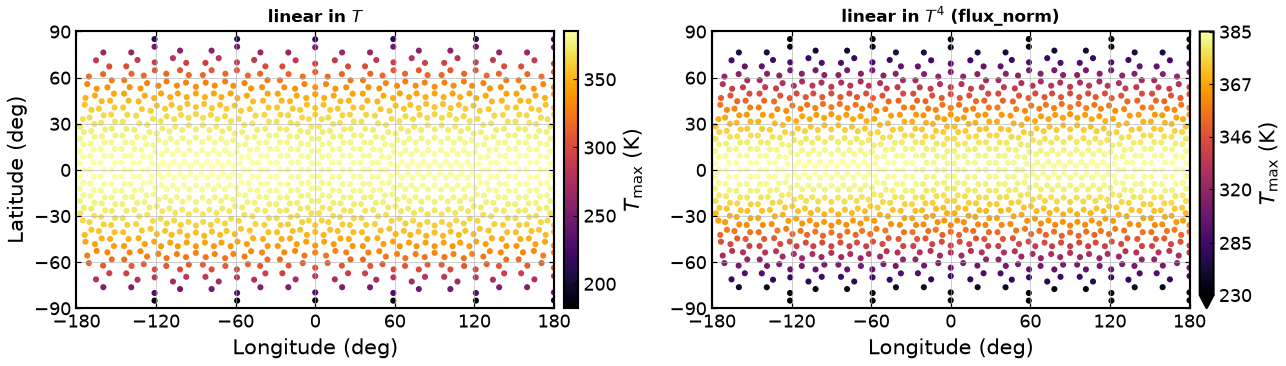

In [7]:
from matplotlib.colors import Normalize
from ptm import plots

plt = plots.styled()                 # the project's figure style
tmax = moon.stat("temperature", "max")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, norm, title in ((axes[0], Normalize(tmax.min(), tmax.max()), "linear in $T$"),
                        (axes[1], plots.flux_norm(tmax), "linear in $T^4$ (flux_norm)")):
    art = plots.scatter_map(ax, moon.lat, moon.lon, tmax, norm=norm, title=title,
                            ylabel=(ax is axes[0]))
    plots.colorbar(fig, art, ax, r"$T_\mathrm{max}$ (K)", tmax, norm,
                   pad=0.02, fraction=0.046)
fig.tight_layout()

Both panels show the same numbers. On the left, the middle half of the faces share about a fifth
of the color range, and the sunlit hemisphere is a single pale color. On the right, the same faces
are separated and the polar gradient is visible.

Each dot is one face at its own center. `plots.scatter_map` does not interpolate.

## 6. The diurnal cycle at one face

`plot_diurnal` selects the face nearest a given latitude and longitude and plots
its whole time series.

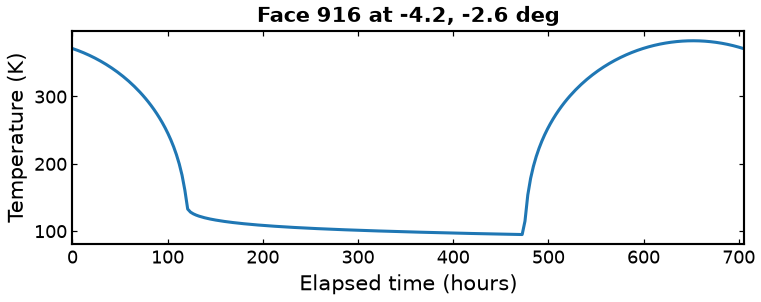

In [8]:
fig = moon.plot_diurnal(lat=0, lon=0)

The curve is one lunar day, a slow rise of about 350 hours to noon and a slower fall. For this
face the peak temperature and the peak insolation fall in the same output step, so the thermal
lag is shorter than the 3-hour sampling (exercise 2 resolves it).

Thermal inertia shows most clearly in the shape of the night. The insolation drops to zero at
sunset within one step, but the temperature does not follow. The surface cools quickly for the
first several hours as the shallow layer radiates, and then cools slowly and almost linearly for
the rest of the 450-hour night. The slow cooling is heat conducted up from the warmer regolith
below. This is the nighttime plateau Diviner observes.

## 7. Day/night contrast against latitude

Tmax - Tmin: 114.7 to 290.5 K, mean 265.2 K; correlation with |latitude| r = -0.92


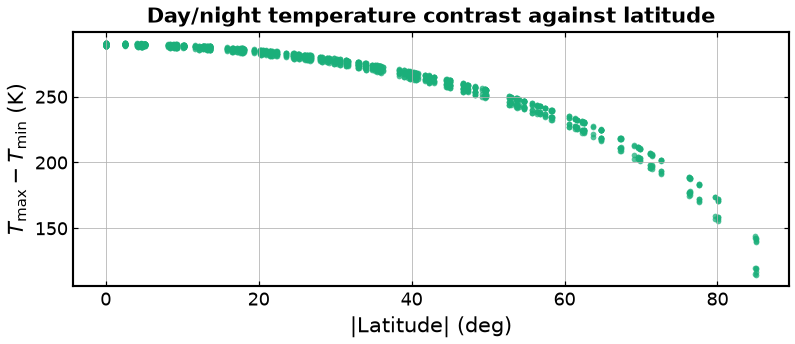

In [9]:
contrast = tmax - moon.stat("temperature", "min")
print(f"Tmax - Tmin: {contrast.min():.1f} to {contrast.max():.1f} K, "
      f"mean {contrast.mean():.1f} K; correlation with |latitude| "
      f"r = {np.corrcoef(np.abs(moon.lat), contrast)[0, 1]:+.2f}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.scatter(np.abs(moon.lat), contrast, s=14, alpha=0.75, linewidths=0, color="#1baf7a")
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")
ax.set_title("Day/night temperature contrast against latitude")
ax.grid(True, linewidth=0.5)
fig.tight_layout()

The swing falls off cleanly toward the poles. Near the equator the Sun reaches
near-normal incidence at noon, so $T_\mathrm{max}$ approaches the sub-solar
blackbody limit, while the nighttime floor is the same ~90 K everywhere. Toward
the poles grazing incidence caps $T_\mathrm{max}$ well below the equatorial
value and $T_\mathrm{min}$ barely moves, so the swing narrows. This is why the
poles are cold-trap territory before any topographic shadowing enters, and
shadowing, added in [`02_crater_radiosity.md`](../02_crater_radiosity.md), only deepens it.

## 8. One instant instead of a whole lunar day

A statistic over the window and a single output step are different kinds of field. A snapshot
has a hot day side and a cold night side, with many faces at each end of the range, so it is not
compressed and a linear scale suits it. `plot_globes` therefore uses the flux scale for the
maximum temperature and a linear scale for a single step.

The `+` marks the subsolar point, read from `body_positions.csv`, which gives the Sun vector in the
body-fixed frame at every output step. At the step shown, the Sun is over the far side, so the
near side is in lunar night.

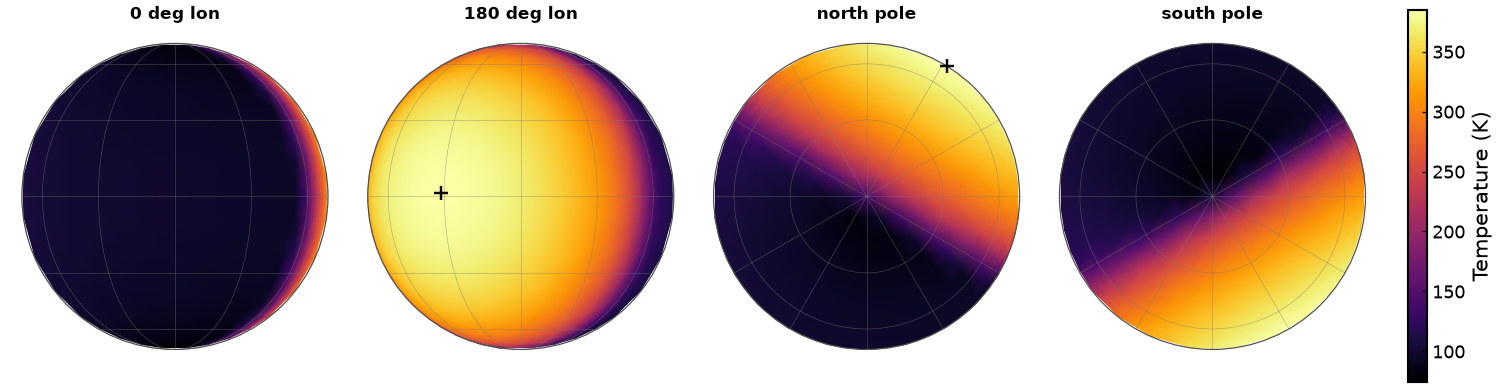

In [10]:
step = len(moon.times().et) // 2
fig = moon.plot_globes("temperature", step=step, mark_subsolar=True)

## 9. The same run on lunar topography

Everything so far uses a perfect sphere. PTM3D can instead move every vertex of the mesh to the
lunar radius measured by the LRO laser altimeter (LOLA). This tilts each face by the local slope
and changes the angle at which sunlight arrives.

The topography, property maps and albedo maps are downloaded separately from the repository.

```bash
python3 scripts/fetch_data.py --dataset moon-topo --dataset moon-property-maps --dataset albedo-maps
```

Two configurations make the comparison. They differ in one key, `mesh.use_topographic`. Both use
a level-5 icosphere, 29.53 days, 240 steps, the LOLA albedo map and the Diviner H-parameter map.
The two meshes have the same faces in the same order, so the outputs can be compared face by
face.

In [11]:
TOPO = "examples/moon_global_topo_res5.yaml"
FLAT = "examples/moon_global_topo_res5_flat.yaml"
paths.preflight([TOPO, FLAT, "data/topo/moon/topo_moon_ico5.bin"]).raise_if_missing()

WATCH = ("Loading topographic mesh", "Mesh created with", "Simulation completed in")
topo = engine.run_engine(pre.root / TOPO, show=WATCH).results()
flat = engine.run_engine(pre.root / FLAT, show=WATCH).results()

    Mesh created with 10242 vertices and 20480 faces
    Loading topographic mesh from: data/topo/moon/topo_moon_ico5.bin
    Simulation completed in 6.897 seconds (6897 ms)


    Mesh created with 10242 vertices and 20480 faces
    Mesh created with 10242 vertices and 20480 faces
    Simulation completed in 6.696 seconds (6696 ms)


In [12]:
d_tmax = topo.stat("temperature", "max") - flat.stat("temperature", "max")
d_tmin = topo.stat("temperature", "min") - flat.stat("temperature", "min")
print(f"Tmax change (topography - smooth): mean {d_tmax.mean():+.2f} K, "
      f"RMS {d_tmax.std():.2f} K, range {d_tmax.min():+.1f} to {d_tmax.max():+.1f} K")
print(f"Tmin change:                       mean {d_tmin.mean():+.2f} K, "
      f"RMS {d_tmin.std():.2f} K")
print(f"|Tmax change| exceeds 5 K on {100 * np.mean(np.abs(d_tmax) > 5):.1f}% "
      f"of {topo.n_faces} faces")

Tmax change (topography - smooth): mean -0.01 K, RMS 3.45 K, range -72.5 to +112.6 K
Tmin change:                       mean -0.03 K, RMS 0.57 K
|Tmax change| exceeds 5 K on 5.6% of 20480 faces


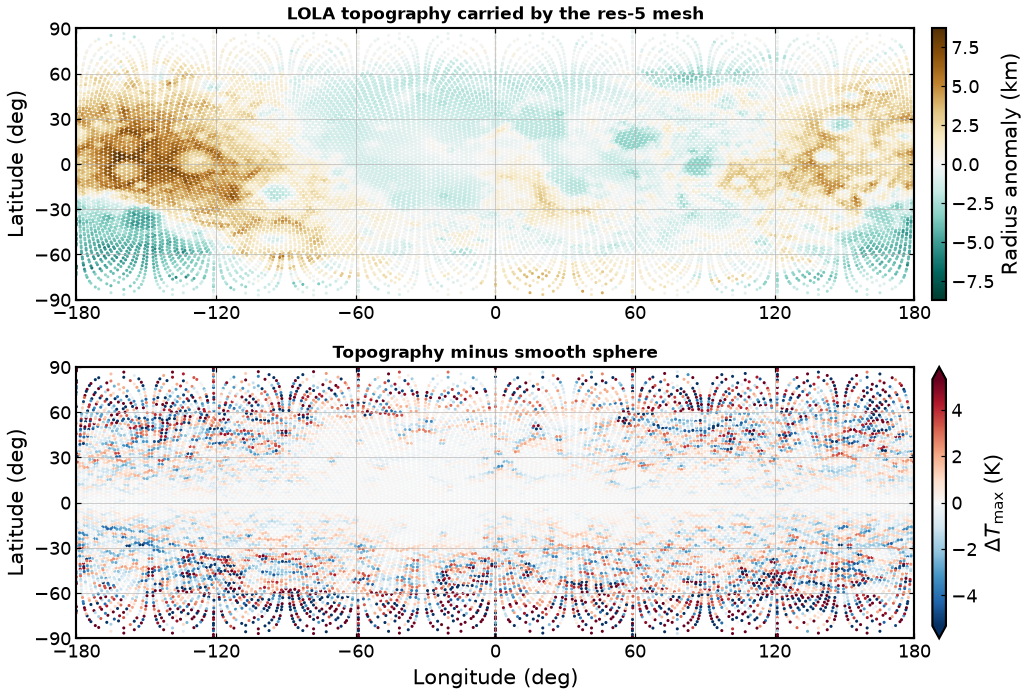

In [13]:
R_MOON_KM = 1737.4
radius = np.linalg.norm(topo.mesh["vertices"], axis=1)
relief = ((radius / np.median(radius) - 1.0) * R_MOON_KM)[topo.mesh["faces"]].mean(axis=1)
norm_d = plots.sym_norm(d_tmax, pct=95.0)

fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.6))
for ax, values, cmap, norm, label, title in (
        (axes[0], relief, "BrBG_r", plots.sym_norm(relief, pct=100.0),
         "Radius anomaly (km)", "LOLA topography carried by the res-5 mesh"),
        (axes[1], d_tmax, plots.CMAP_DIFF, norm_d,
         r"$\Delta T_\mathrm{max}$ (K)", "Topography minus smooth sphere")):
    art = plots.scatter_map(ax, topo.lat, topo.lon, values, cmap=cmap, norm=norm,
                            title=title, xlabel=(ax is axes[-1]))
    plots.colorbar(fig, art, ax, label, values, norm, pad=0.02, fraction=0.046)
fig.tight_layout()

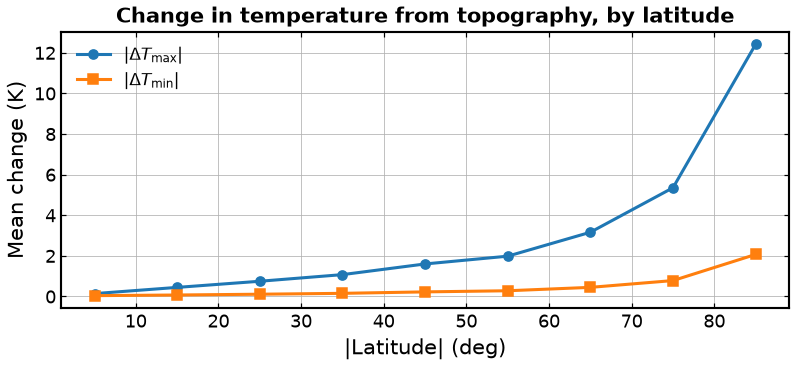

In [14]:
edges = np.arange(0, 91, 10)
abs_lat = np.abs(topo.lat)
binned = lambda d: [np.abs(d[(abs_lat >= a) & (abs_lat < b)]).mean()
                    for a, b in zip(edges[:-1], edges[1:])]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(edges[:-1] + 5, binned(d_tmax), "o-", lw=2, label=r"$|\Delta T_\mathrm{max}|$")
ax.plot(edges[:-1] + 5, binned(d_tmin), "s-", lw=2, label=r"$|\Delta T_\mathrm{min}|$")
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel("Mean change (K)")
ax.set_title("Change in temperature from topography, by latitude")
ax.legend(frameon=False)
ax.grid(True, linewidth=0.5)
fig.tight_layout()

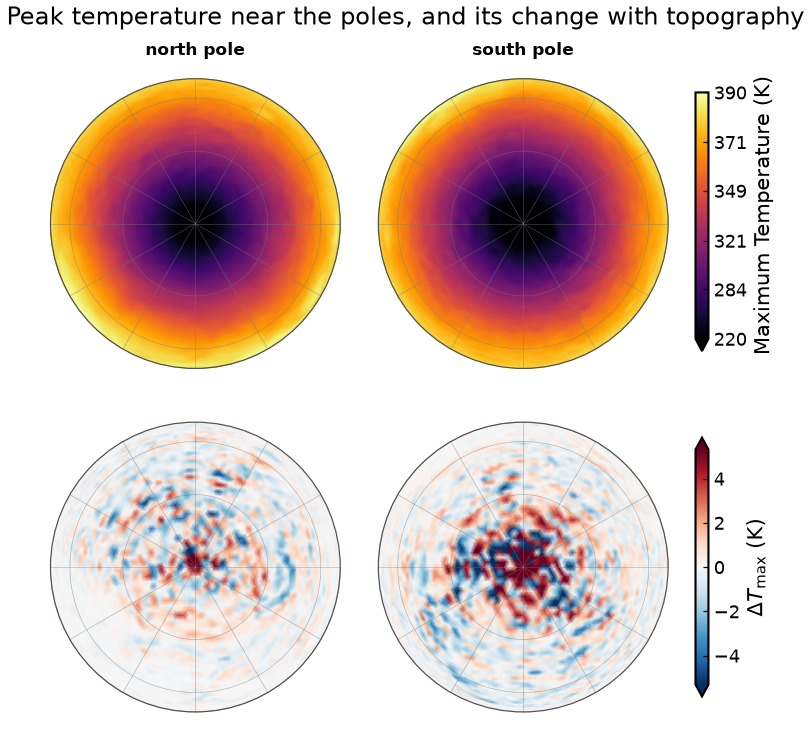

In [15]:
fig = topo.globe_grid(
    rows=[{"what": "temperature", "moment": "max"},
          {"what": d_tmax, "label": r"$\Delta T_\mathrm{max}$ (K)",
           "cmap": plots.CMAP_DIFF, "norm": norm_d}],
    views=[(90, 0, "north pole"), (-90, 0, "south pole")],
    suptitle="Peak temperature near the poles, and its change with topography")

The mean change is small. Averaged over the Moon, topography changes $T_\mathrm{max}$ by
almost nothing, as expected, because a slope facing the noon Sun is balanced elsewhere by one
facing away. The spread is significant, several kelvin RMS, and some faces change by tens of
kelvin.

The effect is concentrated near the poles. The binned curve rises steeply with latitude, for the
same reason as the color scale in section 5. With the Sun high in the sky, a tilt of one degree
barely changes $\cos i$. With the Sun a few degrees above the horizon, the same tilt is a large
fraction of $\cos i$, and faces at grazing incidence change by tens of kelvin. Thermal modeling
of the poles therefore depends on topography, which is why the crater tutorials use DEM meshes
rather than global icospheres.

Night temperatures change little. The change in $T_\mathrm{min}$ is an order of magnitude
smaller. After sunset the minimum is set by the heat the regolith stored and how fast it conducts
that heat, and a slope changes neither.

This comparison has limits. Both runs use the same albedo and H-parameter maps, so the difference
is geometry alone, but at level 5 a face is about 250 km across. That resolves the large basins,
not craters, and with `radiation.enabled: false` no face shadows another. For the shadowing that
makes polar craters cold traps, see [tutorial 2](../02_crater_radiosity.md) and
[tutorial 5](../05_lunar_polar_ice.md).

## 10. Changing a thermophysical property

Changing a surface property and seeing what changes is one of the main uses of a thermal model.
On a built-in body the properties come from a table compiled into the model, and a configuration
reaches them only through the keys listed below. A key that is not on this list has no effect.
This section runs a sweep and shows two checks that confirm it acted.

On a built-in body (`body: Moon`, `body: Europa`, ...) these keys are used.

| To change | Use |
|---|---|
| surface and deep conductivity | `thermophysical.ks_override`, `kd_override` |
| Bond albedo, emissivity | `thermophysical.albedo_override`, `emissivity_override` |
| thermal inertia, one value | `--thermal-inertia`, or `thermophysical.constant_thermal_inertia` |
| thermal inertia, per face | `thermal.thermal_inertia_map` |
| H-parameter, per face | `thermal.h_parameter_map` |
| internal heat flow | `thermal.geothermal_heat_flow`, or per face `thermal.heat_flow_mask_file` |
| the conductivity law | `thermophysical.conductivity_model` |
| the angular dependence of albedo | `thermophysical.incidence_angle_albedo` |

The plain names (`thermophysical.albedo`, `ks`, `kd`, `rhos`, `rhod`, `cp0`, `H`, `Qb`, `chi`) are
not used here. They belong in `generic_body.surface:`, the subject of notebook 03, and the run
prints a warning that lists any of them found under `thermophysical:`. Two more keys in the same
block have no effect on a built-in body, `albedo_hapke_w` and `thermal_n`.

### Two definitions of thermal inertia

$\Gamma = \sqrt{k \rho c_p}$ is not a parameter of the model. A value of $\Gamma = 200$ has to be
reached by changing $k$, $\rho$ or $c_p$, and PTM3D offers two ways.

- `thermal_inertia` (`--thermal-inertia`) sets
  $k_s = \Gamma^2 / (\rho_s\thinspace c_p(273\thinspace\mathrm{K}))$ and scales $k_d$ by the
  same factor. The contrast between surface and depth and the radiative conductivity term $\chi$
  are kept, so the effective thermal inertia still varies with depth and temperature, and 200 is
  a nominal surface value.
- `constant_thermal_inertia` (`--constant-thermal-inertia`, or the key of the same name) derives
  $c_p$ instead and sets $\chi = 0$, $k_d = k_s$ and $\rho_d = \rho_s$, so $\Gamma$ is the same at
  every temperature and depth.

Use the first to scale a realistic regolith column, and the second for a single value that stays
fixed, which is what most radiometric fits report. They are different physics, and the end of
this section compares them. A run cannot be given both.

In [16]:
from ptm import Sweep

ti_sweep = Sweep(pre.root / CONFIG, grid={"thermal_inertia": [100.0, 200.0, 400.0]},
                 outdir=pre.root / "output/moon_thermal_inertia_sweep")
ti_sweep.run()

[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 0f278820ed46c59ca3043c7fe500999a)
[sweep] axis thermal_inertia: 3 values -> --thermal-inertia (engine advertises it)
[sweep]   note (thermal_inertia): this is ks = TI^2/(rhos*cp(273 K)) with kd scaled by the same factor: the depth contrast is preserved and the diffusivity moves with TI. The other convention, constant_thermal_inertia, derives cp instead and collapses the column, giving a measurably different diurnal amplitude on the same config. Choose deliberately.


[sweep] ok   thermal_inertia-100 (8.0 s)


[sweep] ok   thermal_inertia-200 (9.2 s)


[sweep] ok   thermal_inertia-400 (9.5 s)
[sweep] 3 complete, 0 failed, 0 skipped, 26.7 s


{'planned': 3,
 'skipped': 0,
 'complete': 3,
 'failed': 0,
 'not_attempted': 0,
 'wall_seconds': 26.7,
 'dry_run': False}

`Sweep` takes one base configuration, which it does not edit, and a grid, and writes one output
directory for each point. Before it runs, it reports how each value is passed to the model (here
through the `--thermal-inertia` option) and repeats the note about the two definitions.

Two checks confirm that the sweep acted.

First, read the value the thermal model used. The log prints `Property override (requested):`
when the request is read and `[Thermo override] applied at solver:` when the thermal model uses it.
Only the second confirms the change. For `--thermal-inertia` it also shows the conductivities it
computed. $\Gamma = 200$ on the Moon means $k_s = 0.0505$ W/m/K, far from the built-in value of
0.00074.

Second, two points of a sweep must not produce identical output. A checksum of
`statistics/temperature_max.bin` shows whether a swept value changed anything.

In [17]:
import hashlib

digests = []
for point in ti_sweep.points:
    log = (point.dir / "engine.log").read_text().splitlines()
    applied = next((l for l in log if "applied at solver:" in l), "NO OVERRIDE LINE")
    digests.append(hashlib.md5(
        (point.dir / "statistics" / "temperature_max.bin").read_bytes()).hexdigest())
    print(f"TI = {point.params['thermal_inertia']:5.0f}  {digests[-1][:8]}  {applied}")
print(f"\n{len(set(digests))} distinct outputs from {len(digests)} sweep points")

TI =   100  051e26b0  [Thermo override] applied at solver: ks 0.00074 -> 0.012632 W/m/K; kd 0.0034 -> 0.0580388 W/m/K
TI =   200  1983f494  [Thermo override] applied at solver: ks 0.00074 -> 0.0505279 W/m/K; kd 0.0034 -> 0.232155 W/m/K
TI =   400  9026b1da  [Thermo override] applied at solver: ks 0.00074 -> 0.202112 W/m/K; kd 0.0034 -> 0.928621 W/m/K

3 distinct outputs from 3 sweep points


A misspelled key leaves the default in place. The run lists any key it does not recognize, and
any unrecognized command-line option, as a warning before it starts. `ptm.engine_config.unknown_keys`
makes the same check on a configuration in Python before anything is run.

In [18]:
import yaml
from ptm.engine_config import unknown_keys

draft = yaml.safe_load((pre.root / CONFIG).read_text())
draft["thermophysical"]["ks"] = 0.003            # a plain name: not read on a built-in body
draft["thermal"]["equilibration_orbit"] = 4.0    # a misspelling of equilibration_orbits
print("read by nothing:", unknown_keys(draft))

read by nothing: ['thermal.equilibration_orbit', 'thermophysical.ks']


In [19]:
const_sweep = Sweep(pre.root / CONFIG, grid={"constant_thermal_inertia": [200.0]},
                    outdir=pre.root / "output/moon_constant_ti_sweep")
const_sweep.run()

[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 0f278820ed46c59ca3043c7fe500999a)
[sweep] axis constant_thermal_inertia: 1 values -> --constant-thermal-inertia (engine advertises it)
[sweep]   note (constant_thermal_inertia): this is cp = TI^2/(ks*rhos) with chi=0, kd=ks and rhod=rhos: TI is exactly constant in temperature AND depth, and the thermal diffusivity therefore varies along the axis. The other convention, thermal_inertia, scales ks/kd instead, giving a measurably different diurnal amplitude on the same config. Choose deliberately.


[sweep] ok   constant_thermal_inertia-200 (10.3 s)
[sweep] 1 complete, 0 failed, 0 skipped, 10.3 s


{'planned': 1,
 'skipped': 0,
 'complete': 1,
 'failed': 0,
 'not_attempted': 0,
 'wall_seconds': 10.3,
 'dry_run': False}

amplitude at TI = 200: 196.7 K by one convention, 240.8 K by the other (+44.2 K)


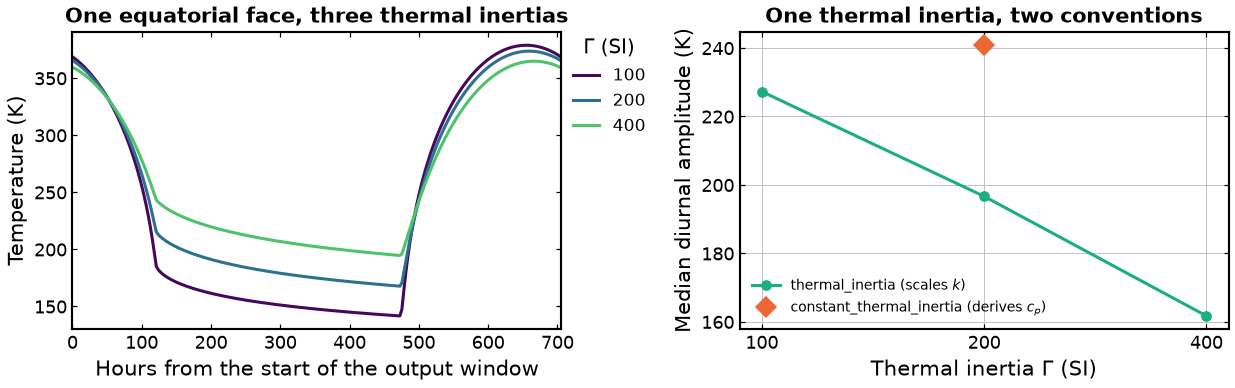

In [20]:
def amplitude(res):
    return float(np.median(res.stat("temperature", "max") - res.stat("temperature", "min")))


ti, amp = ti_sweep.values("thermal_inertia"), ti_sweep.collect(amplitude)
amp_const = amplitude(const_sweep.points[0].results)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ti_sweep.plot_curves(ax=axes[0], lat=0, lon=0, legend_title=r"$\Gamma$ (SI)",
                     xlabel="Hours from the start of the output window",
                     title="One equatorial face, three thermal inertias")
axes[1].plot(ti, amp, "o-", lw=2, color="#1baf7a", label=r"thermal_inertia (scales $k$)")
axes[1].plot([200.0], [amp_const], "D", ms=9, color="#eb6834",
             label=r"constant_thermal_inertia (derives $c_p$)")
axes[1].set_xscale("log")
axes[1].set_xticks(ti)
axes[1].set_xticklabels([f"{v:g}" for v in ti])
axes[1].minorticks_off()
axes[1].set_xlabel(r"Thermal inertia $\Gamma$ (SI)")
axes[1].set_ylabel("Median diurnal amplitude (K)")
axes[1].set_title("One thermal inertia, two conventions")
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(True, linewidth=0.5)
fig.tight_layout()
print(f"amplitude at TI = 200: {amp[1]:.1f} K by one convention, "
      f"{amp_const:.1f} K by the other ({amp_const - amp[1]:+.1f} K)")

The response is the one heat conduction predicts. Raising $\Gamma$ flattens the curve toward its
mean. The median face's diurnal range is 227.3 K at 100 SI, 196.7 K at 200 and 161.7 K at 400. The
left panel shows why. The peak falls a little and the night minimum rises a lot, because a
higher thermal inertia stores more of the day's heat and releases it through the night.

The choice of definition is significant. At a nominal 200 SI the two definitions give 196.7 K and
240.8 K, a difference of 44.2 K, larger than the effect of doubling $\Gamma$ from 100 to 200. A
value of "$\Gamma = 200$" quoted without its definition is ambiguous by about 20% in the result.

None of these three runs is the Moon. The built-in surface conductivity,
$k_s = 7.4\times10^{-4}$ W/m/K, corresponds to $\Gamma = 24$ SI by the first definition. The 50 to
70 SI usually quoted for lunar regolith is an effective value over the diurnal skin depth, which
includes the rise of conductivity with depth and the radiative term. Every run in this sweep
therefore has a warmer, flatter night than the Moon. It is a sensitivity study, not a model of the
Moon.

The sweep varies one property, uniform over the whole body, on a sphere without radiation
exchange, so nothing here describes the response inside a crater. Properties that vary from face
to face are set with maps instead (`thermal.thermal_inertia_map`, and the H-parameter and albedo
maps used in section 9). Notebook 03 repeats the exercise on a body defined in the configuration,
where the plain property names are used.

## 11. Exercises

1. A sharper map. Copy the quickstart configuration, raise `mesh.resolution` from 3 to 4 (1,280 to
   5,120 faces), run section 1 with it and redraw the map of section 5.
   `scripts/ptm_mem_estimate.py --faces 5120 --steps 240` estimates the memory first.

2. The noon lag. The peaks of insolation and temperature share an output step above, so the lag is
   shorter than 3 hours. Raise `simulation.timesteps` from 240 to 960 (about 45 minutes per step)
   and see whether the two peaks separate.

3. Poles and equator. `moon.plot_diurnal(lat=85, lon=0)` needs no new run. Expect a much smaller
   range, as in section 7, and a flatter curve, because sunlight at grazing incidence spreads a
   weaker flux over more of the day.

4. Finer topography. Set `mesh.resolution: 6` in both configurations of section 9 (81,920 faces,
   `topo_moon_ico6.bin` from the same dataset). The mean change should stay near zero while the
   RMS grows, because a finer mesh resolves steeper slopes.

5. Another property. Change the grid of section 10 to `{"albedo": [0.08, 0.12, 0.16]}` to span
   the lunar range, or to `{"thermophysical.emissivity_override": [0.90, 0.95, 1.00]}` to see
   how little emissivity changes the maximum temperature compared with albedo. Use the checksum
   test in both cases.

On a built-in body such as the Moon, plain property names in a configuration are not used
(sections 3 and 10). `Sweep` reaches the keys that are, and notebook 03 works with a body defined
in the configuration, where the plain names are used.